# 原論文のMSゲートモデルによる較正比較：平均ゲート忠実度への統一

**主指標を標準的な平均ゲート忠実度 $F_{\mathrm{avg}}$ に統一する。**
原論文の gate-overlap fidelity は、原論文の数値を再現できているかの確認だけに用いる。
同じ時間発展から両指標を求め、定義の違いを物理モデルの違いと混同しない。

対象：Kirchhoff, Wilhelm and Motzoi, *Correction Formulas for the Mølmer–Sørensen Gate Under Strong Driving*,
[PRX Quantum **6**, 010328 (2025)](https://doi.org/10.1103/PRXQuantum.6.010328)。
[arXiv本文](https://arxiv.org/html/2404.17478v3)のFig. 2 / Fig. 5と同じ矩形パルスの代表点を扱う。
出版版Appendix Bの式(B6)は、arXiv HTMLでは式(58)に相当する。

比較するのは**原論文の同一Hamiltonian上の較正法**。
従来ノートの有効Hamiltonianや散乱・加熱を含む結果と、数値を直接並べて優劣をつけない。
このノートは原論文の矩形パルスに範囲を限定し、全図・全パルスの再現を意味しない。

実行：カーネル **Python (MS Pauli distance)** を選んで上からRun All。
既存の振幅スキャンを照合して再利用し、不足する最適化点・収束確認点だけ計算して保存する。
実装は `kirchhoff_channel_benchmark.py`、出力は `results/kirchhoff_fidelity_channel_comparison/`。
元のノート・キャッシュを変更しない。

## 0．環境と固定した比較条件

$K=\nu T/(2\pi)=28$、$L=\delta T/(2\pi)=25$、$\eta=0.18$、
$\nu/(2\pi)=1\,\mathrm{MHz}$、$T=28\,\mu\mathrm{s}$、$\bar n=0.02$。
原論文のフォノン次元 $N=8$、側帯次数 $|m|\leq3$ を主計算に採用し、後半で打切りの影響を調べる。
全系の時間発展はunitaryだが、運動自由度をトレースした量子ビットチャネルは一般に非unitary。
外部の加熱・散乱・dephasingは追加していない。

図の横軸は原論文と同じ $\Omega/10^6\,\mathrm{s}^{-1}$。
$\Omega/(2\pi)$ のMHz表示とは異なるので、余分な $2\pi$ を入れない。
今回の実行対象は原論文の代表温度であり、以前の $\bar n=0.01,1,2,3,4$ の別モデルでの計算とは区別する。

In [1]:
from pathlib import Path
import os, sys, json, platform, inspect
from dataclasses import asdict
from importlib.metadata import version, PackageNotFoundError

PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                     if (p/'kirchhoff_channel_benchmark.py').is_file()), None)
if PROJECT_ROOT is None:
    raise RuntimeError('プロジェクトのフォルダ内から実行してください。')
sys.path.insert(0, str(PROJECT_ROOT)) if str(PROJECT_ROOT) not in sys.path else None
OUTPUT_DIR = PROJECT_ROOT/'results/kirchhoff_fidelity_channel_comparison'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
os.environ.setdefault('MPLCONFIGDIR', str(OUTPUT_DIR/'.matplotlib'))
print('実行中のPython:', sys.executable)
RUN_SDP = True
RUN_CONVERGENCE = True
if RUN_SDP:
    try:
        import cvxpy as cp
    except ImportError as exc:
        raise ImportError('カーネル Python (MS Pauli distance) を選んでください。'
                          '別のカーネルでは、そのPythonにrequirements-pauli-distance.txtを導入してください。') from exc
    assert 'SCS' in cp.installed_solvers(), cp.installed_solvers()

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from IPython.display import display, Markdown
import kirchhoff_channel_benchmark as kb
import kirchhoff_paper_infidelity as paper
import pauli_channel_distance as pcd

settings = kb.Settings()
NBAR = 0.02
benchmark = kb.Benchmark(OUTPUT_DIR, settings=settings, nbar=NBAR)
labels, paulis = pcd.pauli_basis(2)
pd.set_option('display.max_columns', 24)
pd.set_option('display.precision', 9)
plt.rcParams.update({'figure.dpi': 120, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})
display(pd.DataFrame([dict(n_bar=NBAR, **asdict(settings))]))

実行中のPython: /Library/Developer/CommandLineTools/usr/bin/python3


,n_bar,K,L,eta,gate_duration_seconds,phonon_dim,sideband_cutoff,solver,relative_tolerance,absolute_tolerance,trotter_step_scale,maximum_step_divisor
0,0.02,28.0,25.0,0.18,0.000028,8,3,adaptive_dop853,0.000000001,1.000000000e-11,1.0,20.0


## 1．再利用するモデルと較正条件

既存の `kirchhoff_paper_infidelity.py` が原論文の式(17)–(19)を実装している：

$$H(t)=\hbar\Omega\sum_{m=-m_{\max}}^{m_{\max}}\sum_{\mu=\pm1}
e^{i(m\nu+\mu\delta)t}\,A_m\otimes J_m,$$

$$J_m=\begin{cases}J_x&m\text{ が偶数},\\ iJ_y&m\text{ が奇数},\end{cases}
\qquad J_\alpha=\tfrac12(\sigma_\alpha\otimes I+I\otimes\sigma_\alpha).$$

$A_m$ の行列要素は一般化Laguerre多項式で計算する。ここでは $\eta^2$ の一次側帯補正だけに
置き換えていない。ただしフォノン次元と側帯次数は有限であり、「無限次元の厳密解」ではない。
原論文の $YY$ 目標ゲートを局所 $R_z(-\pi/2)$ で $XX$ に写す。
この写像はPauli演算子の置換なので、今回の忠実度・Pauli近似距離の値を変えない。

較正条件は、解析式 $\Omega_{\rm LD}$［式(32)］、$\Omega_2$［式(35)］、$\Omega_4$［式(41)］、
原論文指標の数値最適化、標準的 $F_{\rm avg}$ の数値最適化、$h_{XX}=0$ の6通り。
すべて振幅1変数を用い、ゲート時間・温度・Hamiltonian・目標ゲートを固定する。
数値最適化は振幅スキャン近傍での局所最適化であり、全制御空間の大域最適性は主張しない。

In [2]:
landmarks = pd.DataFrame([
    {'condition': name, 'Omega / 1e6 s^-1': value/1e6}
    for name, value in settings.landmarks().items()
])
display(landmarks)
# 実際に使用するHamiltonian生成関数を確認できる。
print(inspect.getsource(paper.dimensionless_hamiltonian))

,condition,Omega / 1e6 s^-1
0,Omega_LD,1.050325441
1,Omega_2,1.068899474
2,Omega_4,1.089192470


def dimensionless_hamiltonian(
    model: KirchhoffPaperModel,
    tau: float,
    *,
    omega_times_gate: float,
) -> np.ndarray:
    """Return T H(t)/hbar at dimensionless time tau=t/T."""

    phases = np.exp(2j * np.pi * model.frequencies * float(tau))
    hamiltonian = float(omega_times_gate) * np.einsum(
        "k,kij->ij", phases, model.operators, optimize=True
    )
    # Remove round-off anti-Hermitian components before exponentiation.
    return 0.5 * (hamiltonian + hamiltonian.conj().T)



## 2．Fidelityは何を平均しているのか

原論文の指標は、$U_{mn}=\langle m|U(T)|n\rangle$、目標量子ビットunitaryを $V$ として

$$F_{\rm overlap}=\frac1d\left|\sum_n p_n\operatorname{Tr}(V^\dagger U_{nn})\right|,
\qquad d=4.$$

この式では振幅を足してから絶対値を取る。一方、運動自由度を除いた量子ビットチャネルは

$$\mathcal G(\rho)=\sum_{mn}K_{mn}\rho K_{mn}^\dagger,
\qquad K_{mn}=\sqrt{p_n}\,U_{mn}.$$

標準的な平均ゲート忠実度は、任意の純粋な量子ビット入力をHaar平均した

$$F_{\rm avg}(\mathcal G,V)=\int d\psi\,
\langle\psi|V^\dagger\mathcal G(|\psi\rangle\langle\psi|)V|\psi\rangle
=\frac{dF_e+1}{d+1},$$

$$F_e=\frac1{d^2}\sum_{mn}p_n\left|\operatorname{Tr}(V^\dagger U_{mn})\right|^2.$$

正規化した誤差チャネルの $\chi$ を使えば
$F_e=\chi_{II,II}$、$1-F_{\rm avg}=\frac45(1-\chi_{II,II})$。
[Nielsen (2002)](https://arxiv.org/abs/quant-ph/0205035)の一般チャネルに対する関係式を用いる。

**採用理由**：$F_{\rm avg}$ は縮約量子ビットチャネルそのものの指標であり、
従来のチャネル距離ノートと同じ定義で使える。
一般には $F_{\rm overlap}$ の数値を二乗・定数倍するだけで $F_{\rm avg}$ に変換できない。
$U=I_{\rm motion}\otimes W$ の特殊な場合だけ、$F_e=F_{\rm overlap}^2$ となる。

下の検算では運動モードだけに位相を付け、量子ビットには完全な目標ゲートを作用させる。
$F_{\rm avg}=1$ でも原論文指標は1未満になり得る。この違いが指標を統一する理由であり、
原論文で定義された量自体を計算し直さずに置き換えてよいという意味ではない。

In [3]:
toy_model = paper.build_paper_model(phonon_dim=3)
motion_phase = np.diag(np.exp(1j*np.array([0.0, 1.3, 2.4])))
toy_U = np.kron(motion_phase, toy_model.target_qubit_unitary)
toy_chi, toy = kb.channel_from_propagator(toy_U, toy_model, nbar=0.7)
display(pd.DataFrame([{
    'standard F_avg': toy['standard_average_fidelity'],
    'paper overlap fidelity': toy['paper_average_overlap_fidelity'],
    'Pauli PTM Frobenius': toy['pauli_ptm_frobenius'],
}]))
assert abs(toy['standard_average_fidelity']-1) < 1e-12
assert toy['paper_average_overlap_fidelity'] < 0.9

,standard F_avg,paper overlap fidelity,Pauli PTM Frobenius
0,1.0,0.701883543,1.765344776e-15


## 3．保存済み時間発展の再利用と原論文数値の再現確認

`chi_error_element_nbar_fit.ipynb` の8.1節に対応するキャッシュを利用する。
パラメータ・積分設定から元のハッシュを再計算し、一致したファイルだけ読み込む。
温度重みをかける前の $U(T)$ なので、同じ伝播演算子から忠実度と $\chi$ の両方を導ける。

原論文Appendix Bで報告された2点は**原論文指標同士**で比較する。
この表の報告値を標準的な $1-F_{\rm avg}$ と比較してはいけない。
絶対差・相対差を残し、相対差が消えていない場合には「完全再現」と表現しない。

In [4]:
initial_scan = benchmark.legacy_sweep()
print(f'同じ条件で読み込んだ振幅点: {len(initial_scan)}')
reference_rows = []
reported = {'Omega_2': (0.67e-3, 1.3e-3), 'Omega_4': (2.4e-4, 4.3e-4)}
for condition, (overlap, bell) in reported.items():
    row = benchmark.evaluate(settings.landmarks()[condition]/1e6)
    reference_rows.append({
        'condition': condition,
        'paper_reported_overlap_infidelity': overlap,
        'recomputed_overlap_infidelity': row['paper_average_infidelity'],
        'overlap_absolute_difference': row['paper_average_infidelity']-overlap,
        'overlap_relative_difference': row['paper_average_infidelity']/overlap-1,
        'paper_reported_Bell_infidelity': bell,
        'recomputed_Bell_infidelity': row['paper_bell_infidelity'],
        'standard_average_infidelity': row['standard_average_infidelity'],
    })
reference = pd.DataFrame(reference_rows)
reference.to_csv(OUTPUT_DIR/'paper_reproduction_check.csv', index=False)
display(reference)

同じ条件で読み込んだ振幅点: 14


,condition,paper_reported_overlap_infidelity,recomputed_overlap_infidelity,overlap_absolute_difference,overlap_relative_difference,paper_reported_Bell_infidelity,recomputed_Bell_infidelity,standard_average_infidelity
0,Omega_2,0.00067,0.000707227,0.000037227,0.055563207,0.00130,0.001376296,0.001103086
1,Omega_4,0.00024,0.000281072,0.000041072,0.171134513,0.00043,0.000488073,0.000419690


## 4．同じ物理モデルで振幅を選ぶ

1. 解析式の3点は式の値をそのまま使う。
2. `paper_overlap_opt` は原論文指標の不忠実度を最小化する。
3. `standard_Favg_opt` は主指標 $1-F_{\rm avg}$ を最小化する。
4. `hXX_zero` は、誤差PTMの $\log R$ をHamiltonian生成元へ射影して得た $h_{XX}$ の零点を探す。

2–4は既存の振幅スキャンで極小／符号変化を挟み、Brent法で精密化する。
各候補で**物理振幅を変えて時間発展を計算する**。生成元から $h_{XX}$ を引いた仮想チャネルではない。
Hamiltonian係数の規約は $-i h_{XX}[XX,\rho]$、単位はrad/gate。
$\log R$ を使うことは、任意の誤差チャネルがMarkov半群へ埋め込めるという主張ではない。

In [5]:
selected = benchmark.calibrate()
display(selected[['condition', 'omega_mhz', 'standard_average_infidelity',
                  'paper_average_infidelity', 'h_XX_rad_per_gate']])
assert abs(selected.set_index('condition').loc['hXX_zero', 'h_XX_rad_per_gate']) < 1e-7
display(pd.read_json(OUTPUT_DIR/'calibration.json').T)

,condition,omega_mhz,standard_average_infidelity,paper_average_infidelity,h_XX_rad_per_gate
0,Omega_LD,1.050325441,0.002774870,0.001752344,5.521610603e-02
1,Omega_2,1.068899474,0.001103086,0.000707227,3.020139456e-02
2,Omega_4,1.089192470,0.000419690,0.000281072,2.451236638e-03
3,paper_overlap_opt,1.090245611,0.000417900,0.000280016,9.991895503e-04
4,standard_Favg_opt,1.090276847,0.000417899,0.000280017,9.561046521e-04
5,hXX_zero,1.090969810,0.000418631,0.000280516,3.335461727e-11


,omega_mhz,objective,success,bracket_mhz,nfev,residual_hXX
paper_overlap_opt,1.090245611,paper_average_infidelity,True,"[1.089192470393784, 1.089999999999999, 1.09999...",11,NaN
standard_Favg_opt,1.090276847,standard_average_infidelity,True,"[1.089192470393784, 1.089999999999999, 1.09999...",10,NaN
hXX_zero,1.09096981,NaN,True,"[1.090277940251503, 1.09145898025156]",NaN,0.0


## 5．標準的な平均ゲート忠実度で比較する

左図が主比較、右図は原論文の再現確認。両縦軸の数値を同一の指標として混ぜない。
主比較でも原論文で選ばれた振幅は保持して評価するため、比較のために原論文の較正条件を
勝手に最適化し直したことにはならない。数値最適化した対照群は別の名前で表示する。

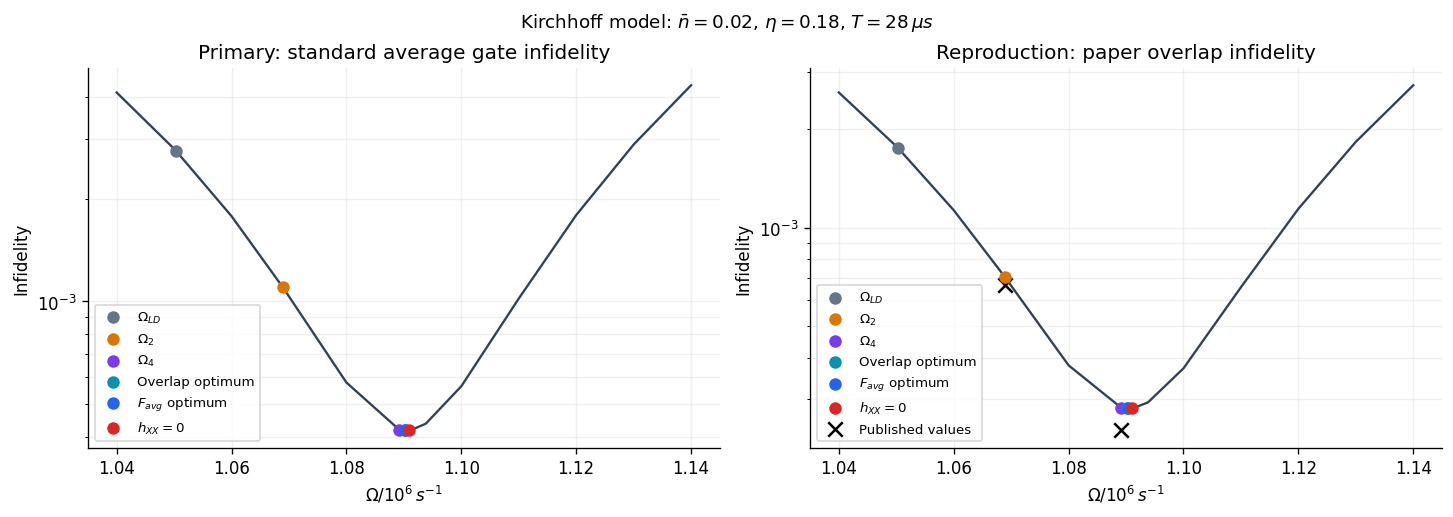

In [6]:
scan = benchmark.table()
colors = dict(zip(selected.condition, ['#64748b', '#d97706', '#7c3aed', '#0891b2', '#2563eb', '#dc2626']))
names = {'Omega_LD': r'$\Omega_{LD}$', 'Omega_2': r'$\Omega_2$',
         'Omega_4': r'$\Omega_4$', 'paper_overlap_opt': 'Overlap optimum',
         'standard_Favg_opt': r'$F_{avg}$ optimum', 'hXX_zero': r'$h_{XX}=0$'}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True)
for ax, column, title in zip(axes,
    ['standard_average_infidelity', 'paper_average_infidelity'],
    ['Primary: standard average gate infidelity', 'Reproduction: paper overlap infidelity']):
    ax.semilogy(scan.omega_mhz, scan[column], color='#334155', lw=1.4)
    for _, row in selected.iterrows():
        ax.scatter(row.omega_mhz, row[column], color=colors[row.condition],
                   label=names[row.condition], s=42, zorder=4)
    ax.set(xlabel=r'$\Omega / 10^6\,s^{-1}$', ylabel='Infidelity', title=title)
    ax.grid(True, which='both', alpha=.2)
for _, row in reference.iterrows():
    axes[1].scatter(settings.landmarks()[row.condition]/1e6,
                    row.paper_reported_overlap_infidelity, marker='x', s=75,
                    color='black', label='Published values' if row.condition=='Omega_2' else None)
axes[0].legend(fontsize=8)
axes[1].legend(fontsize=8)
fig.suptitle(r'Kirchhoff model: $\bar n=0.02$, $\eta=0.18$, $T=28\,\mu s$', fontsize=11)
fig.savefig(OUTPUT_DIR/'fidelity_definitions_comparison.png', dpi=220)
fig.savefig(OUTPUT_DIR/'fidelity_definitions_comparison.pdf')
plt.show()

## 6．$\chi$ とチャネル距離を同じ条件で評価する

規約：$\mathcal E=\mathcal G\circ\mathcal U_*^{-1}$、
$\mathcal E(\rho)=\sum_{ab}\chi_{ab}P_a\rho P_b^\dagger$、$\operatorname{Tr}\chi=1$。
`qp.to_choi`から標準Pauli基底へ変換するので、QuTiPの $Y$ を含む $\chi$ の符号規約に依存しない。
元チャネルをCPTP射影したりトレースで再正規化したりせず、直接、CP・TPと忠実度を確認する。
$F_{\rm avg}$ はKraus式・$\chi$ 式・QuTiP関数の3通りで照合する。

各条件で別々に $\chi_{\rm P}=\operatorname{diag}(\chi)$ を作り、

$$\epsilon_{\rm P}=\tfrac12\|\mathcal E-\mathcal T_{\rm P}(\mathcal E)\|_\diamond,
\qquad\epsilon_{\rm ideal}=\tfrac12\|\mathcal E-\mathcal I\|_\diamond$$

を計算する。前者はPauli近似の精度、後者は理想ゲートへの最悪入力での近さ。
較正法同士のチャネル距離は優劣の指標にしていない。

補助指標は $D_F=\|R-R_{\rm P}\|_F=d\|\chi-\chi_{\rm P}\|_F$。
diamond距離は既存の `pauli_channel_distance.py` のSDP主問題・双対問題を使う。
Choi順序はinput $\otimes$ output、非正規化Choi行列 $J$ のtraceは $d$。
数値的に実行可能な証人から下界・上界を計算し、ギャップが許容値以内でなければ停止する。
これは保存行列についての数値的区間であり、時間発展や物理モデルの誤差保証とは別。

SDPの規約：$\|\Delta\|_\diamond=\max\operatorname{Tr}(JW)$、
$\rho\succeq0$、$\operatorname{Tr}\rho=1$、$-\rho\otimes I\preceq W\preceq\rho\otimes I$。
双対は $Z\succeq\pm J$、$\operatorname{Tr}_{\rm out}Z\preceq tI$ の下で $t$ を最小化する。
距離として報告するときは両方とも $1/2$ を掛ける。

In [7]:
comparison = benchmark.selected_distances(selected, run_sdp=RUN_SDP)
display(comparison[['condition', 'standard_average_infidelity', 'h_XX_rad_per_gate',
                    'pauli_ptm_frobenius', 'pauli_choi_trace_distance']])
if RUN_SDP:
    display(comparison[['condition', 'pauli_diamond_distance_estimate',
                        'pauli_diamond_sdp_lower', 'pauli_diamond_sdp_upper',
                        'ideal_diamond_distance_estimate', 'ideal_diamond_sdp_gap']])
display(comparison[['condition', 'choi_min_eigenvalue', 'choi_tp_frobenius_error',
                    'fidelity_crosscheck_error', 'thermal_tail_mass']])
assert comparison.cptp_within_tolerance.all()
assert comparison.fidelity_crosscheck_error.max() < 1e-9

,condition,standard_average_infidelity,h_XX_rad_per_gate,pauli_ptm_frobenius,pauli_choi_trace_distance
0,Omega_LD,0.002774870,5.521610603e-02,0.311694526,0.055364831
1,Omega_2,0.001103086,3.020139456e-02,0.170908252,0.030505757
2,Omega_4,0.000419690,2.451236638e-03,0.017053631,0.003330840
3,paper_overlap_opt,0.000417900,9.991895503e-04,0.011460850,0.002338070
4,standard_Favg_opt,0.000417899,9.561046521e-04,0.011343643,0.002317257
5,hXX_zero,0.000418631,3.335461727e-11,0.009995092,0.002078144


,condition,pauli_diamond_distance_estimate,pauli_diamond_sdp_lower,pauli_diamond_sdp_upper,ideal_diamond_distance_estimate,ideal_diamond_sdp_gap
0,Omega_LD,0.056733650,0.056733650,0.056733650,0.056763346,1.040182038e-10
1,Omega_2,0.031957801,0.031957801,0.031957801,0.031900470,5.176604909e-10
2,Omega_4,0.004397360,0.004397360,0.004397360,0.004319450,3.766177648e-11
3,paper_overlap_opt,0.002957535,0.002957535,0.002957535,0.002886461,7.044613981e-11
4,standard_Favg_opt,0.002914870,0.002914870,0.002914870,0.002844139,1.271894222e-11
5,hXX_zero,0.002540760,0.002540760,0.002540760,0.002663841,2.441896902e-11


,condition,choi_min_eigenvalue,choi_tp_frobenius_error,fidelity_crosscheck_error,thermal_tail_mass
0,Omega_LD,-3.430827110e-16,4.844010285e-15,1.110223025e-16,2.184935350e-14
1,Omega_2,-1.750221530e-17,8.091240005e-15,2.220446049e-16,2.184935350e-14
2,Omega_4,-1.451635508e-17,8.866219113e-15,2.220446049e-16,2.184935350e-14
3,paper_overlap_opt,-2.764897994e-16,5.505524014e-15,2.220446049e-16,2.184935350e-14
4,standard_Favg_opt,-3.206802699e-16,6.253536372e-15,2.220446049e-16,2.184935350e-14
5,hXX_zero,-3.753339425e-19,3.712825688e-15,3.330669074e-16,2.184935350e-14


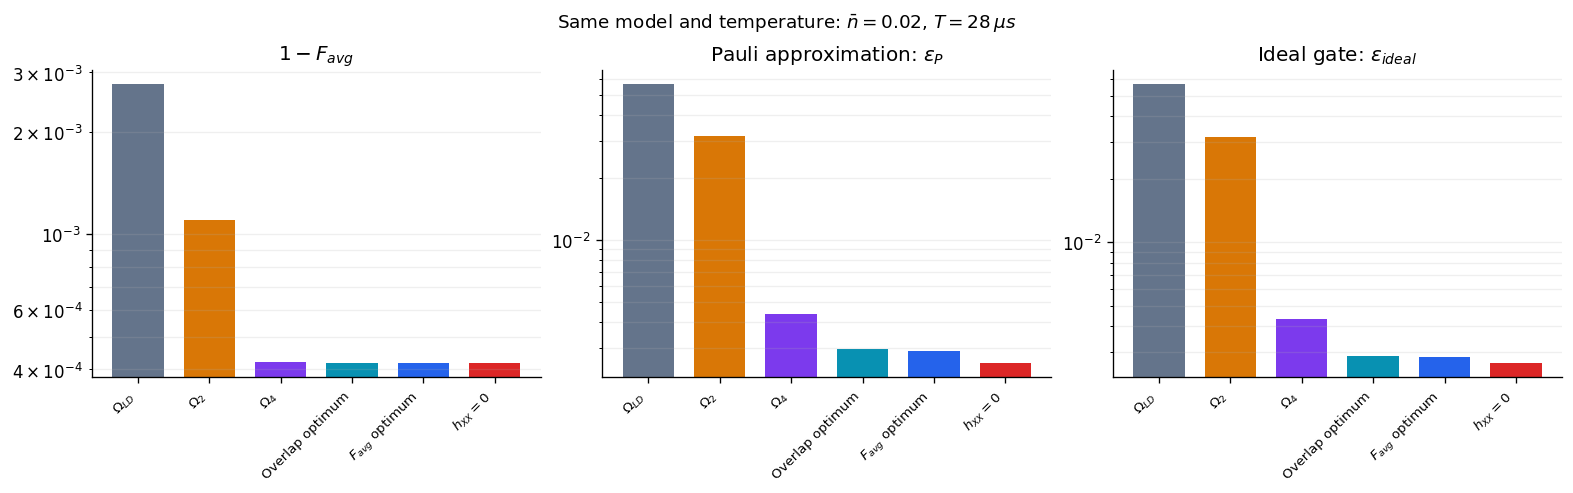

In [8]:
if RUN_SDP:
    fig, axes = plt.subplots(1, 3, figsize=(13, 4), constrained_layout=True)
    columns = ['standard_average_infidelity', 'pauli_diamond_distance_estimate', 'ideal_diamond_distance_estimate']
    titles = [r'$1-F_{avg}$', r'Pauli approximation: $\epsilon_P$', r'Ideal gate: $\epsilon_{ideal}$']
    x = np.arange(len(comparison))
    for ax, column, title in zip(axes, columns, titles):
        ax.bar(x, comparison[column], color=[colors[c] for c in comparison.condition], width=.72)
        ax.set_yscale('log')
        ax.set_xticks(x, [names[c] for c in comparison.condition], rotation=45, ha='right', fontsize=8)
        ax.set_title(title)
        ax.grid(True, axis='y', which='both', alpha=.2)
    fig.suptitle(r'Same model and temperature: $\bar n=0.02$, $T=28\,\mu s$', fontsize=11)
    fig.savefig(OUTPUT_DIR/'channel_metrics_comparison.png', dpi=220)
    fig.savefig(OUTPUT_DIR/'channel_metrics_comparison.pdf')
    plt.show()

## 7．較正後の残留構造

原論文の $\Omega_4$、標準的忠実度最適化、$h_{XX}=0$ を並べる。
誤差の構造を見やすくするため、表示用に $\chi_{II,II}$ のみゼロにする。
これは図の処理であり、距離計算に用いるチャネルから成分を削除していない。
実部・虚部を分け、同じ色スケールで比較する。

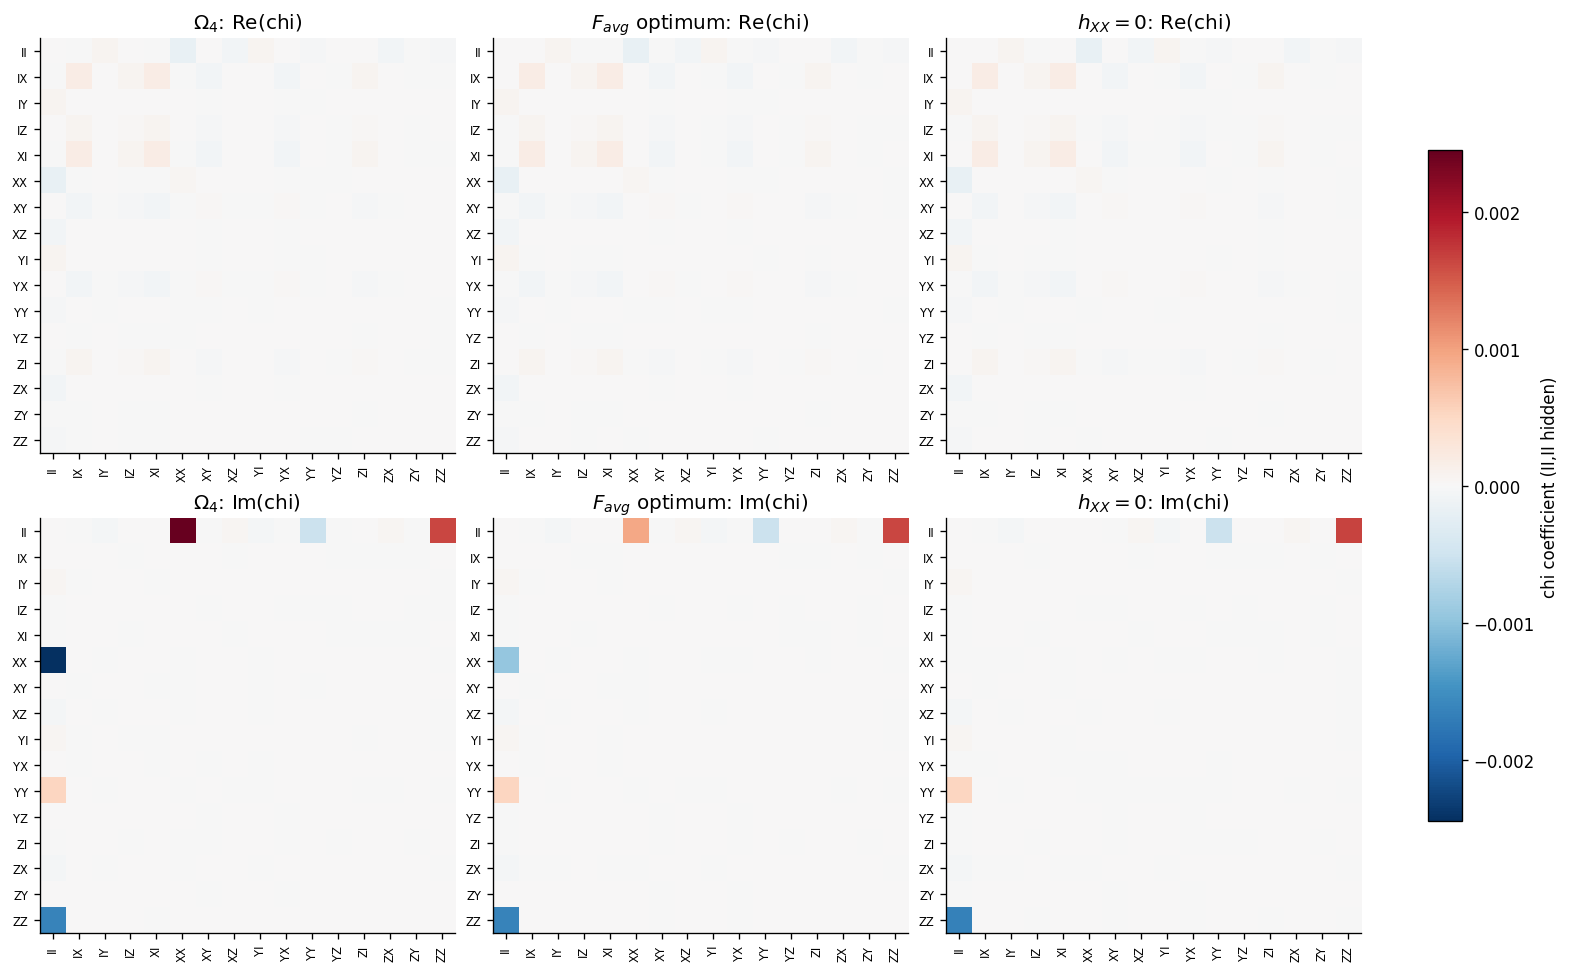

,condition,Pauli pair,Re chi,Im chi,abs chi
0,Omega_4,II / XX,-0.000185603,2.449884533e-03,0.002456905
1,Omega_4,II / ZZ,-0.000027641,1.639243851e-03,0.001639477
2,Omega_4,II / YY,-0.000023922,-5.193563109e-04,0.000519907
3,Omega_4,IX / XI,0.000181516,2.938410234e-19,0.000181516
4,Omega_4,II / YI,0.000063663,-5.301833603e-05,0.000082849
5,Omega_4,II / IY,0.000063663,-5.301833603e-05,0.000082849
6,standard_Favg_opt,II / ZZ,-0.000027085,1.645745337e-03,0.001645968
7,standard_Favg_opt,II / XX,-0.000186598,9.555995619e-04,0.000973647
8,standard_Favg_opt,II / YY,-0.000026503,-5.181097390e-04,0.000518787
9,standard_Favg_opt,IX / XI,0.000182495,-1.052134034e-18,0.000182495


,condition,h_XX_rad_per_gate,h_YY_rad_per_gate,h_ZZ_rad_per_gate
2,Omega_4,2.451236638e-03,-0.000519986,0.001640127
4,standard_Favg_opt,9.561046521e-04,-0.000518700,0.001646673
5,hXX_zero,3.335461727e-11,-0.000517872,0.001650866


In [9]:
focus = ['Omega_4', 'standard_Favg_opt', 'hXX_zero']
matrices = []
for name in focus:
    omega = float(selected.set_index('condition').loc[name, 'omega_per_second'])
    chi = benchmark.channels[omega].copy()
    chi[0, 0] = 0  # display only
    matrices.append(chi)
limit = max(max(abs(c.real).max(), abs(c.imag).max()) for c in matrices)
fig, axes = plt.subplots(2, 3, figsize=(13, 8), constrained_layout=True)
for j, (name, chi) in enumerate(zip(focus, matrices)):
    for i, (part, tag) in enumerate([(chi.real, 'Re'), (chi.imag, 'Im')]):
        im = axes[i,j].imshow(part, cmap='RdBu_r', norm=TwoSlopeNorm(vmin=-limit, vcenter=0, vmax=limit))
        axes[i,j].set_title(f'{names[name]}: {tag}(chi)')
        axes[i,j].set_xticks(range(16), labels, rotation=90, fontsize=7)
        axes[i,j].set_yticks(range(16), labels, fontsize=7)
fig.colorbar(im, ax=axes.ravel().tolist(), shrink=.75, label='chi coefficient (II,II hidden)')
fig.savefig(OUTPUT_DIR/'selected_chi_structure.png', dpi=220)
fig.savefig(OUTPUT_DIR/'selected_chi_structure.pdf')
plt.show()

residual_rows = []
for name in focus:
    omega = float(selected.set_index('condition').loc[name, 'omega_per_second'])
    chi = benchmark.channels[omega]
    pairs = [(a,b) for a in range(16) for b in range(a+1,16)]
    for a,b in sorted(pairs, key=lambda ab: abs(chi[ab]), reverse=True)[:6]:
        residual_rows.append({'condition': name, 'Pauli pair': labels[a]+' / '+labels[b],
                              'Re chi': chi[a,b].real, 'Im chi': chi[a,b].imag, 'abs chi': abs(chi[a,b])})
residual = pd.DataFrame(residual_rows)
residual.to_csv(OUTPUT_DIR/'largest_offdiagonal_chi.csv', index=False)
display(residual)
display(comparison.loc[comparison.condition.isin(focus),
                       ['condition', 'h_XX_rad_per_gate', 'h_YY_rad_per_gate', 'h_ZZ_rad_per_gate']])

## 8．原論文との差と数値収束

比較を成立させるには、SDPの収束だけでなく入力チャネルの収束が必要。
下の検証では較正振幅を固定し、基準 $N=8,|m|\leq3$ から変わる量を記録する。

| 検証 | 変えるもの | 解釈 |
|---|---|---|
| tighter ODE | 許容誤差と最大時間刻み | 同じ有限Hamiltonianの積分誤差 |
| Fock $N=12,16$ | 運動Hilbert空間の次元 | 初期熱分布と時間発展中の打切り |
| $m_{\max}=4,5$, $N=16$ | 含む側帯の次数 | 原論文の側帯打切りモデルからの変化 |
| paper Trotter, half dt | 原論文の刻み設定とその半分 | 数値積分法への依存 |

熱分布の省略確率だけが小さくても、ゲート途中の励起が打切り境界に達する可能性は残る。
そのため、最終的なチャネルそのものの変化も評価する。
`channel_diamond_change_upper` は $\frac12\|\mathcal E_{\rm variant}-\mathcal E_{\rm baseline}\|_\diamond$ の上界。
この上界を $b$ とすると、理想チャネルへの距離の変化は高々 $b$、
Pauli近似距離の変化はtwirlの縮小性と三角不等式により高々 $2b$。

原論文の報告値との相違が積分・打切り変更で説明されるかをここで確認する。
一致しない値に合うようにパラメータを変更することはしない。
打切りを増やすと較正の最適振幅も変わり得るので、ここでは「同じ振幅での感度」と明示する。

In [10]:
if RUN_CONVERGENCE:
    convergence = kb.convergence_checks(OUTPUT_DIR, selected, settings, NBAR)
    display(convergence[['variant', 'condition', 'standard_average_infidelity',
                         'paper_average_infidelity', 'delta_standard_infidelity',
                         'channel_diamond_change_upper']])
    # A conservative check that cutoff changes cannot reverse the observed ranking
    # at these fixed amplitudes. This does not establish reoptimized higher-cutoff optima.
    if RUN_SDP:
        indexed = comparison.set_index('condition')
        ranking_rows = []
        for variant in ['tighter_ODE', 'Fock_N12', 'Fock_N16',
                        'sideband_m4_N16', 'sideband_m5_N16']:
            check = convergence[convergence.variant==variant].set_index('condition')
            bsum = sum(check.loc[name,'channel_diamond_change_upper']
                       for name in ['standard_Favg_opt','hXX_zero'])
            for target, factor in [('pauli',2), ('ideal',1)]:
                margin = (indexed.loc['standard_Favg_opt',f'{target}_diamond_sdp_lower']
                          - indexed.loc['hXX_zero',f'{target}_diamond_sdp_upper'])
                ranking_rows.append({'variant':variant,'distance':target,
                                     'baseline_improvement_lower':margin,
                                     'cutoff_change_allowance':factor*bsum,
                                     'improvement_survives_change':margin>factor*bsum})
        ranking = pd.DataFrame(ranking_rows)
        ranking.to_csv(OUTPUT_DIR/'fixed_control_ranking_checks.csv',index=False)
        display(ranking)
    still_different = (reference.overlap_absolute_difference.abs() > 5e-6).any()
    display(Markdown('**原論文報告値との一致は未達です。** 積分・Fock打切り・側帯次数を変えても、'
                     '報告値との差を説明できていません。著者実装の詳細など、追加確認が必要です。'
                     if still_different else '原論文報告値との差は表示桁の丸め幅以内です。'))
else:
    convergence = None
    print('収束確認は未実行。入力チャネルの数値収束を確認したとは主張しない。')

,variant,condition,standard_average_infidelity,paper_average_infidelity,delta_standard_infidelity,channel_diamond_change_upper
0,baseline_N8_m3,Omega_2,0.001103086,0.000707227,0.000000000e+00,0.000000000e+00
1,baseline_N8_m3,Omega_4,0.000419690,0.000281072,0.000000000e+00,0.000000000e+00
2,baseline_N8_m3,standard_Favg_opt,0.000417899,0.000280017,0.000000000e+00,0.000000000e+00
3,baseline_N8_m3,hXX_zero,0.000418631,0.000280516,0.000000000e+00,0.000000000e+00
4,tighter_ODE,Omega_2,0.001103086,0.000707227,-7.105427358e-15,3.434807309e-14
5,tighter_ODE,Omega_4,0.000419690,0.000281072,1.110223025e-16,4.287056281e-14
6,tighter_ODE,standard_Favg_opt,0.000417899,0.000280017,6.661338148e-16,3.228677990e-14
7,tighter_ODE,hXX_zero,0.000418631,0.000280516,2.220446049e-16,2.127541005e-14
8,Fock_N12,Omega_2,0.001103035,0.000707186,-5.175702555e-08,2.251052121e-07
9,Fock_N12,Omega_4,0.000419630,0.000281024,-6.027040578e-08,2.802853390e-07


,variant,distance,baseline_improvement_lower,cutoff_change_allowance,improvement_survives_change
0,tighter_ODE,pauli,0.000374110,1.071243799e-13,True
1,tighter_ODE,ideal,0.000180298,5.356218995e-14,True
2,Fock_N12,pauli,0.000374110,1.138456812e-06,True
3,Fock_N12,ideal,0.000180298,5.692284060e-07,True
4,Fock_N16,pauli,0.000374110,1.138480439e-06,True
5,Fock_N16,ideal,0.000180298,5.692402197e-07,True
6,sideband_m4_N16,pauli,0.000374110,6.006564336e-06,True
7,sideband_m4_N16,ideal,0.000180298,3.003282168e-06,True
8,sideband_m5_N16,pauli,0.000374110,6.052827444e-06,True
9,sideband_m5_N16,ideal,0.000180298,3.026413722e-06,True


**原論文報告値との一致は未達です。** 積分・Fock打切り・側帯次数を変えても、報告値との差を説明できていません。著者実装の詳細など、追加確認が必要です。

## 9．この比較で言えること・言えないこと

`standard_Favg_opt` と `hXX_zero` の比較が、忠実度を用いる振幅較正に対して
チャネル情報を用いることの利点を調べる直接の比較になる。
$\Omega_4$ からの改善だけでは、単に解析式を数値的に精密化した効果と区別できない。

- $1-F_{\rm avg}$ はゲートの平均品質、$\epsilon_{\rm P}$ はPauliモデルの精度を示す。
- $h_{XX}$ がゼロでも、他のHamiltonian成分や非Pauli散逸成分が消えるとは限らない。
- Pauli近似距離だけを小さくしても良いゲートとは限らないため、理想ゲートとの距離も併記する。
- 本結果は原論文の代表点・矩形パルス・単一モード・外部散逸なしの比較。
  加熱や散乱を含む以前の結果、広い温度範囲、QEC論理誤り率への一般化は未検証。
- 完全なチャネル情報を利用できるシミュレーションでの比較であり、実験の測定回数やSPAM誤差を含む較正コストは評価していない。

In [11]:
by_condition = comparison.set_index('condition')
base, hzero = by_condition.loc['standard_Favg_opt'], by_condition.loc['hXX_zero']
statements = [
    '# 原論文モデルでの較正比較',
    '',
    '主指標は標準的な平均ゲート忠実度 F_avg。原論文 overlap は再現確認用。',
    f'条件: nbar={NBAR}, K={settings.K}, L={settings.L}, eta={settings.eta}, T={settings.gate_duration_seconds:g} s。',
    '',
    f'F_avg最適化: Omega={base.omega_mhz:.9f} ×10^6 s^-1, r={base.standard_average_infidelity:.9g}。',
    f'hXX零点: Omega={hzero.omega_mhz:.9f} ×10^6 s^-1, r={hzero.standard_average_infidelity:.9g}。',
    f'hXX零点での不忠実度の相対変化: {100*(hzero.standard_average_infidelity/base.standard_average_infidelity-1):+.4f}%。',
]
if RUN_SDP:
    for prefix, text in [('pauli', 'Pauli近似とのdiamond距離'), ('ideal', '理想チャネルとのdiamond距離')]:
        old, new = base[f'{prefix}_diamond_distance_estimate'], hzero[f'{prefix}_diamond_distance_estimate']
        statements += [f'{text}: {old:.9g} → {new:.9g} ({100*(1-new/old):.3f}%低減)。']
    gap = max(comparison.pauli_diamond_sdp_gap.max(), comparison.ideal_diamond_sdp_gap.max())
    statements += [f'SDPの最大上下界ギャップ: {gap:.3g}。']
statements += ['', '原論文報告値との相対差（overlap infidelity）:']
for _, row in reference.iterrows():
    statements += [f'- {row.condition}: {100*row.overlap_relative_difference:+.3f}%（絶対差 {row.overlap_absolute_difference:+.4g}）。']
if convergence is not None:
    tighter = convergence[convergence.variant=='tighter_ODE'].channel_diamond_change_upper.max()
    fock = convergence[convergence.variant=='Fock_N16'].channel_diamond_change_upper.max()
    statements += ['', f'積分設定変更によるチャネルdiamond距離の上界: 最大 {tighter:.3g}。',
                   f'Fock N=8→16による同上界: 最大 {fock:.3g}。',
                   '原論文報告値との差は未解消。今回調べた積分精度・打切り変更では説明できない。',
                   '同じ実装内での較正法比較は、原論文の数値を完全再現したという主張とは区別する。',
                   '詳細はconvergence_checks.csvとfixed_control_ranking_checks.csvを参照。']
statements += ['', 'hXX零点でもYY・ZZのHamiltonian成分が残る。従来の外部散逸を含むノートの残差と混同しない。']
summary = '\n\n'.join(line for line in statements if line)
(OUTPUT_DIR/'result_summary.md').write_text(summary)
display(Markdown(summary))

# 原論文モデルでの較正比較

主指標は標準的な平均ゲート忠実度 F_avg。原論文 overlap は再現確認用。

条件: nbar=0.02, K=28.0, L=25.0, eta=0.18, T=2.8e-05 s。

F_avg最適化: Omega=1.090276847 ×10^6 s^-1, r=0.000417898624。

hXX零点: Omega=1.090969810 ×10^6 s^-1, r=0.000418631163。

hXX零点での不忠実度の相対変化: +0.1753%。

Pauli近似とのdiamond距離: 0.00291486995 → 0.00254075986 (12.835%低減)。

理想チャネルとのdiamond距離: 0.00284413933 → 0.00266384092 (6.339%低減)。

SDPの最大上下界ギャップ: 5.18e-10。

原論文報告値との相対差（overlap infidelity）:

- Omega_2: +5.556%（絶対差 +3.723e-05）。

- Omega_4: +17.113%（絶対差 +4.107e-05）。

積分設定変更によるチャネルdiamond距離の上界: 最大 4.29e-14。

Fock N=8→16による同上界: 最大 2.86e-07。

原論文報告値との差は未解消。今回調べた積分精度・打切り変更では説明できない。

同じ実装内での較正法比較は、原論文の数値を完全再現したという主張とは区別する。

詳細はconvergence_checks.csvとfixed_control_ranking_checks.csvを参照。

hXX零点でもYY・ZZのHamiltonian成分が残る。従来の外部散逸を含むノートの残差と混同しない。

## 10．再現性・保存物

既存コードを再利用した箇所：`kirchhoff_paper_infidelity.py`（Hamiltonianと伝播、熱平均）、
`drive_amplitude_calibration.py`（原論文の補正式）、`drive_calibration_qpt_analysis.py`（生成元）、
`pauli_channel_distance.py`（距離・SDP）。新規の比較処理は `kirchhoff_channel_benchmark.py`。

`calibration_comparison.csv` は主比較、`selected_channels.npz` は標準Pauli規約の $\chi$、
`paper_reproduction_check.csv` は原論文値との照合、`convergence_checks.csv` は数値感度。
`provenance.json` と `convergence/provenance_*.json` にパラメータ・元ファイルのSHA256を保存する。
画像はPNG/PDFの両方を保存する。

参考文献：
1. [Kirchhoff et al., PRX Quantum 6, 010328 (2025)](https://doi.org/10.1103/PRXQuantum.6.010328)
2. [Nielsen, Phys. Lett. A 303, 249–252 (2002)](https://arxiv.org/abs/quant-ph/0205035)

In [12]:
def package_version(name):
    try:
        return version(name)
    except PackageNotFoundError:
        return 'not installed'
environment = {'python': sys.version, 'executable': sys.executable,
               'platform': platform.platform(),
               'packages': {name: package_version(name) for name in ['numpy','scipy','pandas','matplotlib','qutip','cvxpy','scs','nbformat','nbclient']},
               'settings': asdict(settings), 'n_bar': NBAR,
               'run_sdp': RUN_SDP, 'run_convergence': RUN_CONVERGENCE}
(OUTPUT_DIR/'environment.json').write_text(json.dumps(environment, indent=2))
benchmark.save_provenance()
print('保存先:', OUTPUT_DIR)
display(pd.DataFrame([{'file': p.name, 'bytes': p.stat().st_size}
                      for p in sorted(OUTPUT_DIR.iterdir()) if p.is_file()]))

保存先: /Users/hirainoa/Desktop/量子/project/Moon_shot__高橋PJ/MS_gate_Hirai/results/kirchhoff_fidelity_channel_comparison


,file,bytes
0,amplitude_sweep.csv,20626
1,calibration.json,710
2,calibration_comparison.csv,10577
3,channel_metrics_comparison.pdf,23889
4,channel_metrics_comparison.png,82513
5,convergence_checks.csv,25964
6,environment.json,887
7,fidelity_definitions_comparison.pdf,27732
8,fidelity_definitions_comparison.png,163258
9,fixed_control_ranking_checks.csv,779
